# Deliverable 2: regularising the feed-forward network (27 styles)

Same method as `05_02_regularization_genre`, on the style subset: 27 styles, about 5,200 training images.

The final network of `04_01_feed_forward_style` (try 7: 4 x 4 average pooling, then 256-128, Adam, learning rate 1e-4)
learns the training images by heart: in `04_01`, its validation loss is lowest at epoch 6 (3.135) and rises afterwards,
while its training accuracy reaches 90 % at epoch 30, against about 12 % on validation. This notebook tests the tools of
the course against over-fitting (S06, *"the first fix is always more data. When we cannot, we regularise"*),
**one at a time**, on that same network.

| Tool (S06) | Idea (S06) | What we test |
|---|---|---|
| Weight decay (L2) | keep the weights small | AdamW, six values of λ |
| Dropout | do not rely on any single neuron | p = 0.1, 0.3, 0.5 |
| Batch norm | keep each layer's inputs well scaled | `nn.BatchNorm1d` after each hidden `nn.Linear` |
| Early stopping | stop at the best validation epoch | patience of 5 epochs on the validation loss, best weights restored |

Same rules as every notebook of the team: same data split, same seed, same network, **one change at a time**,
every choice made on the validation set, the test set used **once**, at the end.

### Same protocol as the genres

The settings are those of `05_02_regularization_genre`, so that the two tasks can be compared:

- 30 epochs for every run, best epoch read on validation;
- AdamW for every run (with λ = 0 it is exactly Adam), plus one run with `Adam(weight_decay=1e-4)`, the setting of the
  first regularisation notebook;
- the grid of λ goes directly from 0.01 to 100: on the genres, λ = 10 was the best value and λ = 30 and 100 showed where
  the network under-fits; here we check whether the same values hold with twice as many updates per epoch;
- the same rule to choose the final network, written before looking at the results (part 8).

| Part | What we do |
|---|---|
| 0 | Setup and data (the team's shared pipeline) |
| 1 | One network builder with two switches: dropout and batch norm |
| 2 | Training protocol and sanity checks |
| 3 | Reference: try 7 again, for 30 epochs |
| 4 | Weight decay: Adam versus AdamW, six values of λ |
| 5 | Dropout: three rates |
| 6 | Batch normalisation |
| 7 | Comparison of all the runs |
| 8 | Early stopping, choice of the final network, test (once) and cost for the kiosk |

## 0. Setup

In [1]:
import copy
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Find the root of the repository (the folder that contains src/museum_guide), wherever Jupyter was started,
# so that "import museum_guide" finds the team's code
here = Path.cwd()
ROOT = next((p for p in [here, *here.parents] if (p / "src" / "museum_guide").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"src/museum_guide not found above {here}: put this notebook in the notebooks/ folder of the repository")
sys.path.insert(0, str(ROOT / "src"))
print("repository root:", ROOT)

# Our own package: the same data pipeline and training functions for every model
from museum_guide.data import prepare_subset
from museum_guide.training import count_parameters, evaluate, fit

# Fix the random seed so that every run gives the same results
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load, split, standardise and batch the style subset (takes about a minute)
style = prepare_subset("style")
n_classes = len(style["classes"])
print("device:", device, "| classes:", n_classes, "| train batches:", len(style["train_loader"]))

N_EPOCHS = 30          # same budget as the eight tries of 04_01, for every run of this notebook
LEARNING_RATE = 1e-4   # learning rate of try 7, unchanged
loss_fn = nn.CrossEntropyLoss()

FIG_DIR = ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "results"

repository root: /Users/carlachaume/Documents/M2/Neural_Networks
device: cpu | classes: 27 | train batches: 82


## 1. One network builder for every experiment

The network is the one of try 7 (`04_01`). We add two switches, **off by default**, so that the default network is
exactly try 7. Inside each hidden block the order is:

`nn.Linear` → `nn.BatchNorm1d` (if switched on) → `nn.ReLU` → `nn.Dropout` (if p > 0)

- Batch norm normalises the output of the linear layer, *before* the activation, as in S06.
- Dropout comes after the activation : it switches off whole neurons.
- The output layer stays a plain `nn.Linear`: one logit per class, no dropout and no batch norm on the logits.

In [2]:
def make_mlp(n_classes, image_shape=(3, 32, 32), hidden_sizes=(256, 128), dropout=0.0, batch_norm=False):
    """Build a feed-forward network (MLP) for colour images, with optional dropout and batch norm.

    Args:
        n_classes: number of classes to predict (27 styles or 11 genres).
        image_shape: shape of one input image, (channels, height, width).
        hidden_sizes: number of neurons of each hidden layer.
        dropout: probability of switching off each hidden neuron during training (0 = no dropout).
        batch_norm: if True, add nn.BatchNorm1d after each hidden nn.Linear.

    Returns:
        An nn.Sequential that maps a batch (B, C, H, W) to (B, n_classes) logits.
    """
    # Turn each image into a vector: (B, 3, 32, 32) -> (B, 3072)
    layers = [nn.Flatten()]
    n_in = image_shape[0] * image_shape[1] * image_shape[2]
    for n_out in hidden_sizes:
        layers.append(nn.Linear(n_in, n_out))
        if batch_norm:
            layers.append(nn.BatchNorm1d(n_out))  # normalise each neuron over the mini-batch (S06)
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))    # switch off each neuron with probability p (S06)
        n_in = n_out
    # Output layer: one score (logit) per class, no softmax since CrossEntropyLoss applies it
    layers.append(nn.Linear(n_in, n_classes))
    model = nn.Sequential(*layers)

    # He initialisation, recommended for ReLU networks (TP05 Part D)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model


def make_pooled_mlp(n_classes, pool_size=4, hidden_sizes=(256, 128), dropout=0.0, batch_norm=False):
    """Average pooling followed by the network of make_mlp, as in try 7 of 04_01.

    Returns:
        An nn.Sequential that maps a batch (B, 3, 128, 128) to (B, n_classes) logits.
    """
    pooled_side = 128 // pool_size  # for example 128 // 4 = 32
    return nn.Sequential(
        nn.AvgPool2d(pool_size),     # each block of pool_size x pool_size pixels -> its mean, no weight to learn
        make_mlp(n_classes, (3, pooled_side, pooled_side), hidden_sizes, dropout, batch_norm),
    )


# Check: the default network has the 823,067 parameters of try 7 (04_01)
print("try 7          :", f"{count_parameters(make_pooled_mlp(n_classes)):,} parameters")
print("with dropout   :", f"{count_parameters(make_pooled_mlp(n_classes, dropout=0.3)):,} parameters (dropout has no weight)")
print("with batch norm:", f"{count_parameters(make_pooled_mlp(n_classes, batch_norm=True)):,} parameters "
      "(+ 2 per hidden neuron: scale gamma and shift beta)")
print(make_pooled_mlp(n_classes, dropout=0.3, batch_norm=True))

try 7          : 823,067 parameters
with dropout   : 823,067 parameters (dropout has no weight)
with batch norm: 823,835 parameters (+ 2 per hidden neuron: scale gamma and shift beta)
Sequential(
  (0): AvgPool2d(kernel_size=4, stride=4, padding=0)
  (1): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=256, bias=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=128, out_features=27, bias=True)
  )
)


## 2. Training protocol and sanity checks

Every run starts from the same initial weights (seed 0) and sees the mini-batches in the same order, and only **one**
setting changes. The optimiser is **AdamW** for every run. With $\lambda = 0$, AdamW does exactly the same steps as Adam,
so the reference run is exactly try 7 of `04_01`.

Every run lasts 30 epochs: we read the whole curves (S06: *"overfitting is read on the curves: train loss down,
validation loss up. Always plot both"*) and keep, for each run, the epoch with the best validation accuracy, as in `04_01`.

In [3]:
runs = {}     # name of the run -> history returned by fit
configs = {}  # name of the run -> settings, to retrain the chosen one at the end


def train_run(name, dropout=0.0, batch_norm=False, weight_decay=0.0, decoupled=True, n_epochs=N_EPOCHS):
    """Build a fresh try-7 network with the given settings and train it, like train_style_pooled_mlp in 04_01.

    Args:
        name: name of the run, used in the summary tables.
        dropout, batch_norm: switches of make_pooled_mlp.
        weight_decay: lambda of the L2 regularisation (0 = none).
        decoupled: True for AdamW (real weight decay), False for Adam (L2 added to the gradient).
        n_epochs: number of epochs.

    Returns:
        (model, history): the trained network and the history returned by fit.
    """
    torch.manual_seed(0)  # same initial weights and same order of the mini-batches for every run
    model = make_pooled_mlp(n_classes, dropout=dropout, batch_norm=batch_norm).to(device)
    optimiser_class = torch.optim.AdamW if decoupled else torch.optim.Adam
    optimizer = optimiser_class(model.parameters(), lr=LEARNING_RATE, weight_decay=weight_decay)
    print(f"--- {name} ---")
    history = fit(model, style["train_loader"], style["val_loader"], loss_fn, optimizer, n_epochs, device=device)
    runs[name] = history
    configs[name] = {"dropout": dropout, "batch_norm": batch_norm, "weight_decay": weight_decay, "decoupled": decoupled}
    return model, history


def summarise(names):
    """One row per run: best validation accuracy, its epoch, lowest validation loss and final training accuracy."""
    rows = []
    for name in names:
        h = runs[name]
        best_acc = max(h["val_acc"])
        rows.append({
            "run": name,
            "best epoch": h["val_acc"].index(best_acc) + 1,
            "best val accuracy": round(best_acc, 3),
            "lowest val loss": round(min(h["val_loss"]), 3),
            "epoch of lowest val loss": h["val_loss"].index(min(h["val_loss"])) + 1,
            "train accuracy, last epoch": round(h["train_acc"][-1], 3),
        })
    return pd.DataFrame(rows).set_index("run")


def plot_history(history, title=""):
    """Plot the loss and accuracy curves of one run, train versus validation, as in 04_01."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].legend()
    axes[1].plot(epochs, history["train_acc"], label="train")
    axes[1].plot(epochs, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title)
    plt.show()


def plot_compare(names, title="", file_name=None):
    """Validation loss and validation accuracy of several runs on the same axes."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for name in names:
        h = runs[name]
        epochs = range(1, len(h["val_loss"]) + 1)
        axes[0].plot(epochs, h["val_loss"], label=name)
        axes[1].plot(epochs, h["val_acc"], label=name)
    axes[0].set(xlabel="epoch", ylabel="validation loss")
    axes[1].set(xlabel="epoch", ylabel="validation accuracy")
    axes[1].axhline(1 / n_classes, ls=":", c="k", label="chance")
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[1].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    if file_name:
        fig.savefig(FIG_DIR / file_name, dpi=150)  # saved for the slides
    plt.show()

**Sanity checks before training (S06).**

1. An untrained network that knows nothing predicts $1/C$ everywhere, so its loss is about $\ln C = \ln 27 = 3.30$.
   On the genres the initial loss was a little above $\ln C$ (3.00 for 2.40), because the output layer also uses He
   initialisation: what matters is that the accuracy is at chance level.
2. Dropout and batch norm behave differently in training and in evaluation: in `model.train()` dropout switches neurons
   off at random, in `model.eval()` it is off. We check that `evaluate` (shared code) puts the network in evaluation mode:
   two evaluations of a network with dropout must give exactly the same loss.

In [4]:
torch.manual_seed(0)
check_model = make_pooled_mlp(n_classes, dropout=0.5).to(device)

# 1. Initial loss close to ln(C)
initial_loss, initial_acc = evaluate(check_model, style["val_loader"], loss_fn, device=device)
print(f"initial validation loss {initial_loss:.3f} (ln {n_classes} = {math.log(n_classes):.3f}) "
      f"| accuracy {initial_acc:.3f} (chance {1 / n_classes:.3f})")

# 2. Dropout is random in train mode and switched off in evaluation mode
xb, _ = next(iter(style["val_loader"]))
xb = xb[:8].to(device)
check_model.train()
print("train mode, two passes identical:", torch.equal(check_model(xb), check_model(xb)), "(expected False)")
check_model.eval()
with torch.no_grad():
    print("eval mode,  two passes identical:", torch.equal(check_model(xb), check_model(xb)), "(expected True)")

check_model.train()  # leave it in train mode: evaluate must switch to eval mode by itself
loss_a, _ = evaluate(check_model, style["val_loader"], loss_fn, device=device)
loss_b, _ = evaluate(check_model, style["val_loader"], loss_fn, device=device)
print("evaluate gives the same loss twice:", loss_a == loss_b, "(expected True: evaluate calls model.eval())")

initial validation loss 4.045 (ln 27 = 3.296) | accuracy 0.036 (chance 0.037)
train mode, two passes identical: False (expected False)
eval mode,  two passes identical: True (expected True)
evaluate gives the same loss twice: True (expected True: evaluate calls model.eval())


## 3. Reference: try 7 again, for 30 epochs

No regularisation. With the same seed, the first 12 epochs should be those of try 7 in `04_01`
(validation accuracy 0.136 at epoch 12). On the genres, the same check gave a small difference, because `04_02` was run on
another computer: the seed fixes the initial weights and the order of the mini-batches, not the rounding of floating-point
operations.

--- reference (try 7) ---
epoch  1 | train loss 3.025 acc 0.148 | val loss 3.234 acc 0.115 | 4.8 s
epoch  2 | train loss 2.812 acc 0.200 | val loss 3.174 acc 0.098 | 0.8 s
epoch  3 | train loss 2.634 acc 0.261 | val loss 3.138 acc 0.118 | 1.6 s
epoch  4 | train loss 2.503 acc 0.309 | val loss 3.166 acc 0.121 | 0.9 s
epoch  5 | train loss 2.363 acc 0.354 | val loss 3.122 acc 0.118 | 1.4 s
epoch  6 | train loss 2.241 acc 0.406 | val loss 3.124 acc 0.123 | 0.6 s
epoch  7 | train loss 2.136 acc 0.441 | val loss 3.145 acc 0.114 | 0.8 s
epoch  8 | train loss 2.019 acc 0.483 | val loss 3.150 acc 0.130 | 0.6 s
epoch  9 | train loss 1.904 acc 0.530 | val loss 3.162 acc 0.131 | 0.8 s
epoch 10 | train loss 1.817 acc 0.559 | val loss 3.174 acc 0.134 | 0.6 s
epoch 11 | train loss 1.738 acc 0.577 | val loss 3.202 acc 0.129 | 0.6 s
epoch 12 | train loss 1.639 acc 0.618 | val loss 3.213 acc 0.122 | 0.6 s
epoch 13 | train loss 1.568 acc 0.642 | val loss 3.233 acc 0.135 | 0.5 s
epoch 14 | train loss 1.4

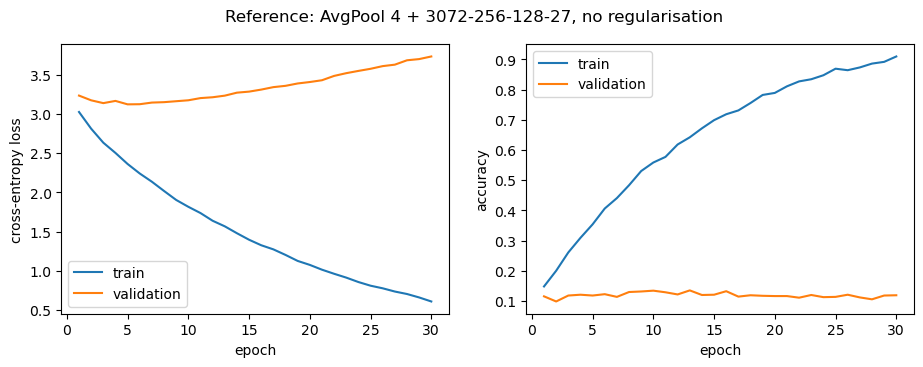

In [5]:
reference_model, reference_history = train_run("reference (try 7)")
print(f"validation accuracy at epoch 12: {reference_history['val_acc'][11]:.3f} (04_01, try 7: 0.136)")
plot_history(reference_history, "Reference: AvgPool 4 + 3072-256-128-27, no regularisation")

**Reading.** The reference shows the same over-fitting pattern as on the genres, even stronger: the training loss falls from 3.03 to 0.61 and the training accuracy rises from 15 % to 91 %, while the validation loss reaches its minimum at epoch 5 (3.122) and then rises steadily to 3.73 at epoch 30. The validation accuracy stays flat between 0.10 and 0.14 (best 0.135, at epoch 13): the network becomes more confident in its wrong answers rather than making more mistakes. At epoch 30 the gap between training and validation accuracy is about 79 points, larger than on the genres (70 points): with 27 classes and fewer than 200 training images per style, there is even more to memorise.

## 4. Weight decay (L2)
 We add a penalty on large weights to the cost: $J_{reg}(W) = J(W) + \frac{\lambda}{2}\lVert W\rVert^2$.
Its gradient is $\lambda w$, so each update becomes

$$w \leftarrow (1-\eta\lambda)\,w - \eta\,\frac{\partial J}{\partial w}$$

At every step the weight is first multiplied by $1-\eta\lambda$, slightly below 1 (it *decays* towards 0), then the usual
step is applied. A weight that the data do not need shrinks to 0; a useful weight is kept by its gradient.

**Adam or AdamW?** `torch.optim.Adam(weight_decay=λ)` adds $\lambda w$ to the gradient, and Adam then divides every gradient
by its own running scale $\sqrt{v}$: the weights with large gradients are hardly decayed at all. This is no longer the
update above. `torch.optim.AdamW` applies the decay $(1-\eta\lambda)$ directly, outside Adam's scaling: this is the
*"decoupled version, for Adam"* of S06.

**Which values of λ?** With AdamW the decay of one step is $\eta\lambda$, and here $\eta = 10^{-4}$. The cell below computes
what is left, after the 30 epochs, of a weight that the data do not need ($(1-\eta\lambda)^{\text{steps}}$). This tells us
which values can have an effect at all.

In [6]:
WD_GRID = [0.01, 0.1, 1.0, 10.0, 30.0, 100.0]
n_steps = N_EPOCHS * len(style["train_loader"])  # number of updates in 30 epochs
print(f"{n_steps} updates in {N_EPOCHS} epochs, learning rate {LEARNING_RATE:g}")
for lam in WD_GRID:
    left = (1 - LEARNING_RATE * lam) ** n_steps
    print(f"lambda = {lam:<5g} decay per step {LEARNING_RATE * lam:.0e} -> an unused weight keeps {left:.1%} of its value")

2460 updates in 30 epochs, learning rate 0.0001
lambda = 0.01  decay per step 1e-06 -> an unused weight keeps 99.8% of its value
lambda = 0.1   decay per step 1e-05 -> an unused weight keeps 97.6% of its value
lambda = 1     decay per step 1e-04 -> an unused weight keeps 78.2% of its value
lambda = 10    decay per step 1e-03 -> an unused weight keeps 8.5% of its value
lambda = 30    decay per step 3e-03 -> an unused weight keeps 0.1% of its value
lambda = 100   decay per step 1e-02 -> an unused weight keeps 0.0% of its value


With $\eta = 10^{-4}$, $\lambda = 0.01$ (the usual default) changes almost nothing. On the genres, λ = 10 was the best value,
λ = 30 under-fitted and λ = 100 collapsed. The style subset has 82 mini-batches per epoch instead of 37, so the same λ
decays the weights more over 30 epochs (cell above): we test the same six values to see whether the optimum moves.
We also run the setting of the first regularisation notebook (Adam, $\lambda = 10^{-4}$), to compare Adam and AdamW.

--- Adam + L2 1e-4 (first notebook setting) ---
epoch  1 | train loss 3.026 acc 0.147 | val loss 3.226 acc 0.120 | 1.4 s
epoch  2 | train loss 2.815 acc 0.196 | val loss 3.176 acc 0.104 | 0.6 s
epoch  3 | train loss 2.637 acc 0.261 | val loss 3.139 acc 0.114 | 0.7 s
epoch  4 | train loss 2.508 acc 0.306 | val loss 3.163 acc 0.123 | 0.7 s
epoch  5 | train loss 2.368 acc 0.351 | val loss 3.134 acc 0.112 | 0.7 s
epoch  6 | train loss 2.243 acc 0.404 | val loss 3.126 acc 0.123 | 0.6 s
epoch  7 | train loss 2.142 acc 0.439 | val loss 3.152 acc 0.119 | 0.6 s
epoch  8 | train loss 2.023 acc 0.480 | val loss 3.145 acc 0.123 | 0.6 s
epoch  9 | train loss 1.904 acc 0.529 | val loss 3.158 acc 0.130 | 0.6 s
epoch 10 | train loss 1.818 acc 0.561 | val loss 3.165 acc 0.133 | 0.6 s
epoch 11 | train loss 1.740 acc 0.580 | val loss 3.189 acc 0.131 | 0.7 s
epoch 12 | train loss 1.644 acc 0.621 | val loss 3.202 acc 0.123 | 0.7 s
epoch 13 | train loss 1.575 acc 0.634 | val loss 3.222 acc 0.134 | 1.2 s
epo

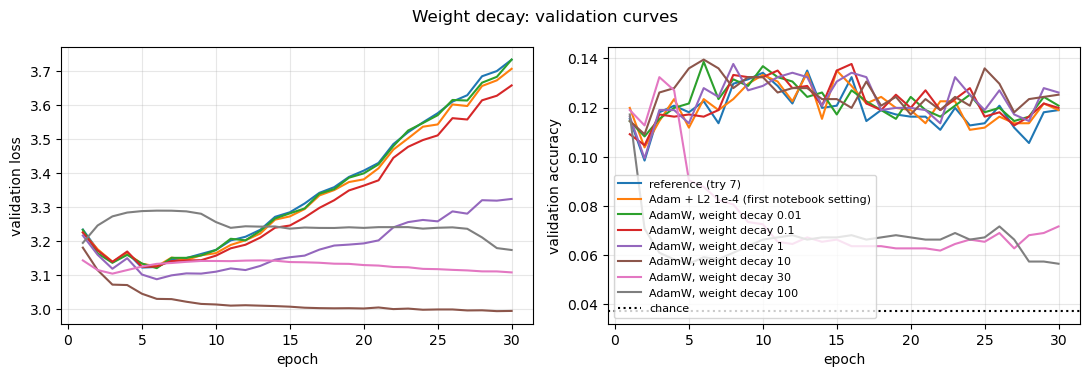

,best epoch,best val accuracy,lowest val loss,epoch of lowest val loss,"train accuracy, last epoch"
run,,,,,
reference (try 7),13,0.135,3.122,5,0.910
Adam + L2 1e-4 (first notebook setting),15,0.135,3.126,6,0.908
"AdamW, weight decay 0.01",6,0.139,3.121,6,0.909
"AdamW, weight decay 0.1",16,0.138,3.124,5,0.902
"AdamW, weight decay 1",8,0.138,3.088,6,0.842
"AdamW, weight decay 10",6,0.140,2.995,29,0.178
"AdamW, weight decay 30",3,0.132,3.105,3,0.080
"AdamW, weight decay 100",1,0.117,3.174,30,0.065


In [7]:
train_run("Adam + L2 1e-4 (first notebook setting)", weight_decay=1e-4, decoupled=False)
for lam in WD_GRID:
    train_run(f"AdamW, weight decay {lam:g}", weight_decay=lam)

wd_names = ["reference (try 7)", "Adam + L2 1e-4 (first notebook setting)"] + [f"AdamW, weight decay {lam:g}" for lam in WD_GRID]
plot_compare(wd_names, "Weight decay: validation curves", "reg_style_weight_decay.png")
summarise(wd_names)

**Reading.** With λ ≤ 0.1, and with Adam + L2 1e-4, the curves are on top of the reference (validation loss rising to 3.66–3.73, 90 % training accuracy): the decay per step is too small. λ = 1 has a moderate effect (validation loss 3.32 at epoch 30 instead of 3.73, 84 % training accuracy). With λ = 10 the memorisation almost disappears: the validation loss falls until the end (2.995, the lowest of all runs) and the training accuracy drops to 17.8 %, against 57 % with the same λ on the genres, close to the validation accuracy (12–13 %). λ = 30 under-fits and λ = 100 collapses: their validation accuracy falls to 0.06–0.07 after epoch 5.

The optimum moved down, as the decay computed above predicts: the style subset has 82 mini-batches per epoch instead of 37, so the same λ shrinks the weights much more over 30 epochs, and λ = 10 here behaves almost like λ = 30 on the genres.

Unlike the genres, no λ improves the validation accuracy: all the runs stay within ±0.5 point of the reference (0.135), and the best value of λ = 10 (0.140) is a single epoch, not a consistently higher curve. Note also that λ = 30 has a low validation loss (3.11) but a very poor accuracy (0.065): a network that hesitates between all classes gets a moderate loss while being almost always wrong, so loss and accuracy can disagree.

## 5. Dropout

 During training, each hidden neuron is switched off (set to 0) with probability $p$, a new random choice
at every mini-batch. The neurons that stay on are multiplied by $1/(1-p)$, so that the expected value of each activation does
not change. The network cannot rely on any single neuron. In `model.eval()` dropout is off and every neuron is used.

We test three rates around the value of the first notebook (0.3).

Careful when reading the table: `fit` measures the training accuracy *during* the epoch, with dropout on. The training
accuracy of a dropout run is therefore measured on a weakened network, and looks lower than the network really is.
The fair comparison is on **validation**, where dropout is off for every run.

--- dropout 0.1 ---
epoch  1 | train loss 3.067 acc 0.131 | val loss 3.237 acc 0.101 | 2.0 s
epoch  2 | train loss 2.898 acc 0.183 | val loss 3.178 acc 0.112 | 0.8 s
epoch  3 | train loss 2.768 acc 0.225 | val loss 3.142 acc 0.123 | 0.6 s
epoch  4 | train loss 2.654 acc 0.264 | val loss 3.105 acc 0.124 | 0.8 s
epoch  5 | train loss 2.559 acc 0.305 | val loss 3.111 acc 0.112 | 0.6 s
epoch  6 | train loss 2.468 acc 0.343 | val loss 3.101 acc 0.127 | 0.6 s
epoch  7 | train loss 2.371 acc 0.375 | val loss 3.108 acc 0.112 | 0.7 s
epoch  8 | train loss 2.292 acc 0.402 | val loss 3.115 acc 0.120 | 1.2 s
epoch  9 | train loss 2.197 acc 0.438 | val loss 3.107 acc 0.123 | 1.1 s
epoch 10 | train loss 2.118 acc 0.464 | val loss 3.130 acc 0.130 | 2.0 s
epoch 11 | train loss 2.040 acc 0.489 | val loss 3.137 acc 0.122 | 0.8 s
epoch 12 | train loss 1.965 acc 0.517 | val loss 3.142 acc 0.128 | 0.7 s
epoch 13 | train loss 1.912 acc 0.530 | val loss 3.173 acc 0.127 | 0.7 s
epoch 14 | train loss 1.826 acc

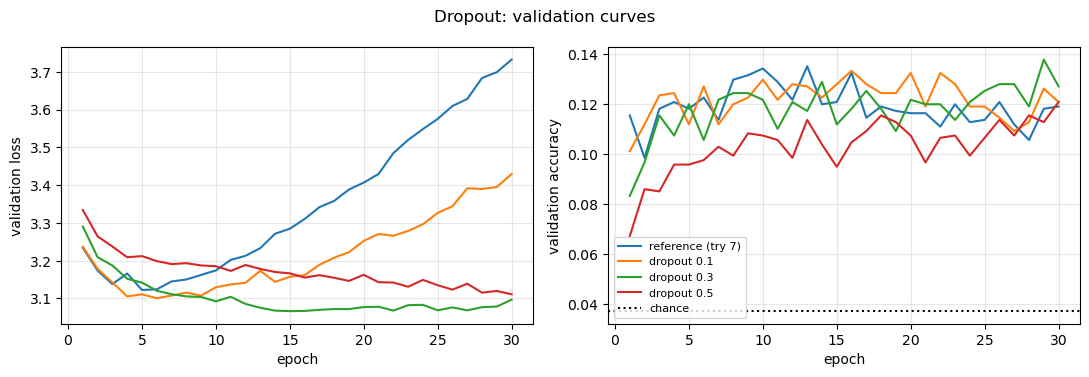

,best epoch,best val accuracy,lowest val loss,epoch of lowest val loss,"train accuracy, last epoch"
run,,,,,
reference (try 7),13,0.135,3.122,5,0.910
dropout 0.1,16,0.133,3.101,6,0.824
dropout 0.3,29,0.138,3.066,15,0.614
dropout 0.5,30,0.121,3.111,30,0.329


In [8]:
DROPOUT_GRID = [0.1, 0.3, 0.5]
for p in DROPOUT_GRID:
    train_run(f"dropout {p:g}", dropout=p)

dropout_names = ["reference (try 7)"] + [f"dropout {p:g}" for p in DROPOUT_GRID]
plot_compare(dropout_names, "Dropout: validation curves", "reg_style_dropout.png")
summarise(dropout_names)

**Reading.** As on the genres, dropout reduces over-fitting in proportion to p. The validation loss of the reference rises from epoch 5 to 3.73; with p = 0.1 it rises later and less (3.43 at epoch 30); with p = 0.3 it stays flat around 3.07–3.10 (lowest 3.066 at epoch 15); with p = 0.5 it is still slowly falling at epoch 30 (3.111). Memorisation drops in the same order: 91 %, 82 %, 61 % and 33 % training accuracy at epoch 30 (measured with dropout on, so slightly underestimated).

The validation accuracy does not improve. p = 0.1 and 0.3 stay mixed with the reference (best 0.133 and 0.138, within the standard error of about 1 point; the 0.138 of p = 0.3 is a single epoch, 29). p = 0.5 is even below the reference for most of the run (0.09–0.11): with half of its neurons switched off, it learns too slowly for 27 classes, and only catches up at epoch 30 (0.121). Dropout makes the network less confident in its wrong answers, not better at recognising styles.

## 6. Batch normalisation

 For each neuron, batch norm subtracts the mean and divides by the standard deviation **over the
mini-batch**, then applies a learnt scale $\gamma$ and shift $\beta$ (2 parameters per neuron). The inputs of every layer
stay well scaled during training. In `model.eval()` it uses running averages of the mean and variance computed during
training, so a single kiosk image can be classified. Because each image is normalised with the other images of its
mini-batch, batch norm also adds a little noise during training, which acts as a mild regularisation.

One change only: batch norm after each hidden `nn.Linear`, same learning rate (1e-4) and no dropout.
The training set has 5,212 images, so the last mini-batch has 5,212 − 81 × 64 = 28 images: batch norm works normally.

--- batch norm ---
epoch  1 | train loss 3.137 acc 0.119 | val loss 3.329 acc 0.089 | 1.9 s
epoch  2 | train loss 2.905 acc 0.179 | val loss 3.212 acc 0.097 | 0.6 s
epoch  3 | train loss 2.726 acc 0.234 | val loss 3.150 acc 0.114 | 0.7 s
epoch  4 | train loss 2.580 acc 0.292 | val loss 3.124 acc 0.118 | 0.8 s
epoch  5 | train loss 2.447 acc 0.348 | val loss 3.115 acc 0.118 | 1.1 s
epoch  6 | train loss 2.323 acc 0.399 | val loss 3.108 acc 0.116 | 1.0 s
epoch  7 | train loss 2.208 acc 0.443 | val loss 3.123 acc 0.123 | 1.1 s
epoch  8 | train loss 2.089 acc 0.484 | val loss 3.116 acc 0.131 | 0.7 s
epoch  9 | train loss 1.986 acc 0.536 | val loss 3.122 acc 0.124 | 1.4 s
epoch 10 | train loss 1.889 acc 0.577 | val loss 3.149 acc 0.107 | 1.4 s
epoch 11 | train loss 1.793 acc 0.607 | val loss 3.154 acc 0.120 | 1.2 s
epoch 12 | train loss 1.679 acc 0.661 | val loss 3.173 acc 0.113 | 0.9 s
epoch 13 | train loss 1.594 acc 0.679 | val loss 3.175 acc 0.121 | 1.1 s
epoch 14 | train loss 1.509 acc 

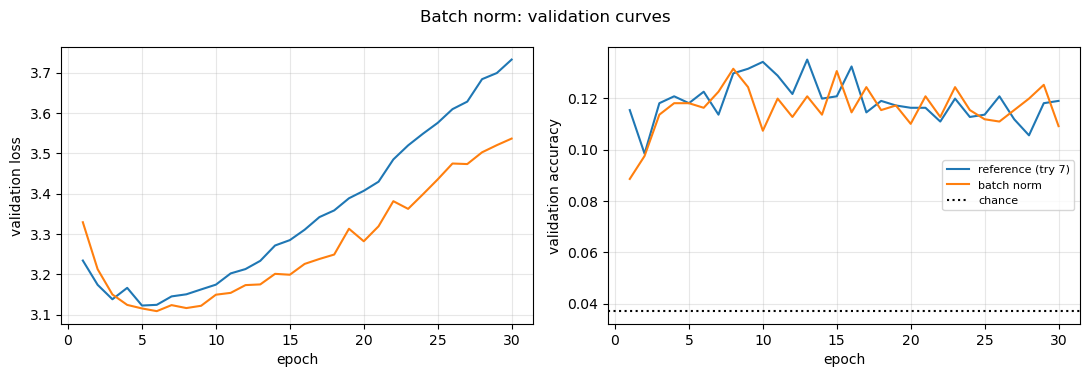

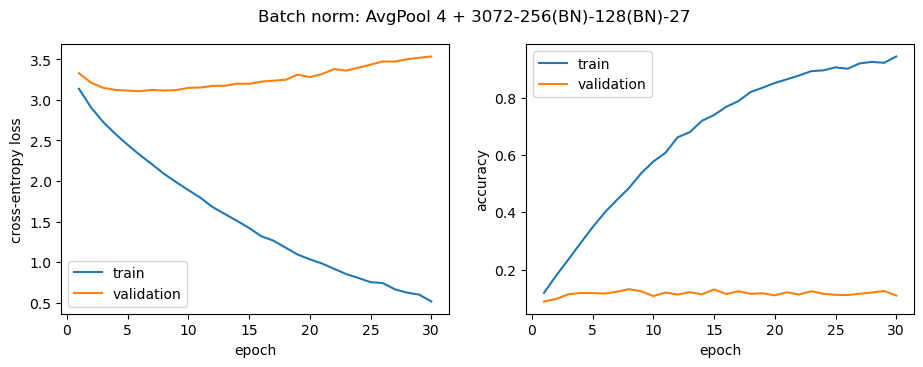

,best epoch,best val accuracy,lowest val loss,epoch of lowest val loss,"train accuracy, last epoch"
run,,,,,
reference (try 7),13,0.135,3.122,5,0.910
batch norm,8,0.131,3.108,6,0.943


In [9]:
train_run("batch norm", batch_norm=True)

bn_names = ["reference (try 7)", "batch norm"]
plot_compare(bn_names, "Batch norm: validation curves", "reg_style_batch_norm.png")
plot_history(runs["batch norm"], "Batch norm: AvgPool 4 + 3072-256(BN)-128(BN)-27")
summarise(bn_names)

**Reading.** As on the genres, batch norm only slows the rise of the validation loss: its minimum is at the same point as the reference (epoch 6, 3.108, against 3.122 at epoch 5), then it rises to about 3.54 at epoch 30 instead of 3.73. It does not reduce memorisation: the training accuracy at epoch 30 is even slightly higher (94.3 % vs 91.0 %) and the training loss lower. Batch norm makes the training images easier to fit, which is its first role in S06 (keeping each layer’s inputs well scaled); it is not a regulariser here. The validation accuracy does not improve: the curve stays mixed with the reference, often slightly below, with a best of 0.131 at epoch 8, against 0.135 for the reference, within the noise.

## 7. Comparison of all the runs

How big is the noise? With $n$ validation images and an accuracy $p$, the standard error of the measured accuracy is
$\sqrt{p(1-p)/n}$. A difference smaller than this is not evidence that one setting is better.

In [10]:
summary = summarise(list(runs)).sort_values("best val accuracy", ascending=False)
n_val = len(style["val_idx"])
p_ref = summary.loc["reference (try 7)", "best val accuracy"]
noise = math.sqrt(p_ref * (1 - p_ref) / n_val)
print(f"{n_val} validation images: standard error about {noise:.3f} ({noise * 100:.1f} points)")
summary["gain vs reference (points)"] = ((summary["best val accuracy"] - p_ref) * 100).round(1)
summary

1118 validation images: standard error about 0.010 (1.0 points)


,best epoch,best val accuracy,lowest val loss,epoch of lowest val loss,"train accuracy, last epoch",gain vs reference (points)
run,,,,,,
"AdamW, weight decay 10",6,0.140,2.995,29,0.178,0.5
"AdamW, weight decay 0.01",6,0.139,3.121,6,0.909,0.4
"AdamW, weight decay 0.1",16,0.138,3.124,5,0.902,0.3
"AdamW, weight decay 1",8,0.138,3.088,6,0.842,0.3
dropout 0.3,29,0.138,3.066,15,0.614,0.3
reference (try 7),13,0.135,3.122,5,0.910,0.0
Adam + L2 1e-4 (first notebook setting),15,0.135,3.126,6,0.908,0.0
dropout 0.1,16,0.133,3.101,6,0.824,-0.2
"AdamW, weight decay 30",3,0.132,3.105,3,0.080,-0.3


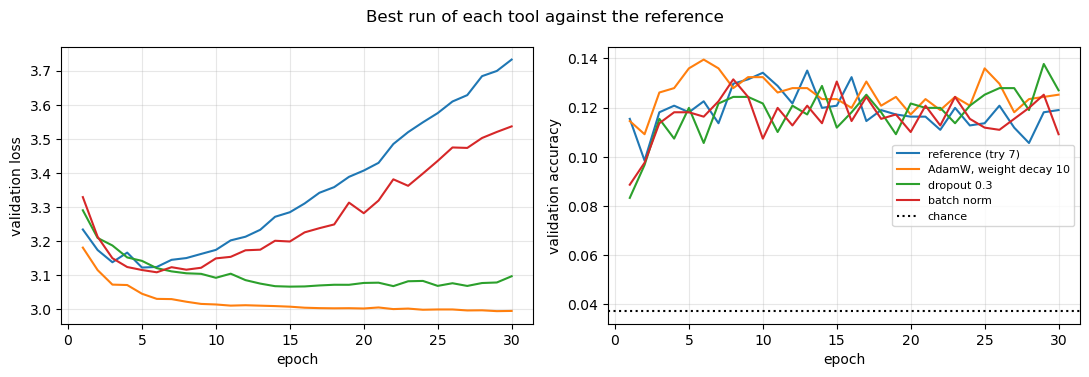

In [11]:
# Best run of each family, against the reference
best_of = lambda names: max(names, key=lambda n: max(runs[n]["val_acc"]))
family_best = ["reference (try 7)",
               best_of([f"AdamW, weight decay {lam:g}" for lam in WD_GRID]),
               best_of([f"dropout {p:g}" for p in DROPOUT_GRID]),
               "batch norm"]
plot_compare(family_best, "Best run of each tool against the reference", "reg_style_comparison.png")

**Reading.** With 1,118 validation images, the standard error is about 1.0 point. No run beats the reference by more than that: the best gain is +0.5 point (AdamW, λ = 10), and all the runs lie between −1.8 and +0.5 points.

The figure shows the same two effects as on the genres. Against over-fitting, weight decay 10 and dropout 0.3 work: the validation loss of weight decay 10 keeps falling (2.995, 18 % training accuracy) and that of dropout 0.3 stays flat (about 3.07–3.10, 61 %), against a rise to 3.73 and 91 % for the reference; batch norm only slows the rise (3.54). On accuracy, nothing stands out: weight decay 10 is slightly above the others between epochs 3 and 8, then the four curves stay mixed between 0.11 and 0.14.

On the styles, regularisation removes the memorisation but brings no accuracy at all, even less than on the genres: with 27 classes on raw pixels, the limit is clearly the input, not the training.

## 8. Early stopping and the final network

### 8.1 Early stopping

 After each epoch, we measure the validation loss. When it improves we keep a copy of
the weights; when it has not improved for `patience` epochs in a row, we stop and **restore the best weights**. So far we
trained every run for 30 epochs and *read* the best epoch afterwards; early stopping does it during training and returns
the network of the best epoch.

We watch the **validation loss** rather than the accuracy, as in the ResNet notebooks: the loss changes smoothly, while the
accuracy jumps by whole images. Patience: 5 epochs.

The training loop is the five lines of the course (forward, loss, `zero_grad`, `backward`, `step`); after each epoch the
network is measured in evaluation mode with the shared `evaluate`.

In [12]:
def fit_early_stopping(model, train_loader, val_loader, loss_fn, optimizer, max_epochs=N_EPOCHS, patience=5):
    """Train with early stopping on the validation loss, and restore the weights of the best epoch (TP06 Ex. 10).

    Args:
        model, train_loader, val_loader, loss_fn, optimizer: as for fit.
        max_epochs: maximum number of epochs.
        patience: number of epochs without improvement of the validation loss before stopping.

    Returns:
        (history, best_epoch): the history (same keys as fit) and the epoch whose weights were restored.
    """
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    best_loss, best_epoch, best_state, waited = float("inf"), 0, None, 0
    for epoch in range(1, max_epochs + 1):
        start = time.time()
        model.train()  # dropout on, batch norm uses the statistics of each mini-batch
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)               # 1. forward
            loss = loss_fn(logits, yb)       # 2. loss
            optimizer.zero_grad()            # 3. reset the gradients
            loss.backward()                  # 4. backpropagation
            optimizer.step()                 # 5. update
        epoch_time = time.time() - start

        # Measure train and validation in evaluation mode (dropout off, batch norm with running statistics)
        model.eval()
        train_loss, train_acc = evaluate(model, train_loader, loss_fn, device=device)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device=device)
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc, epoch_time]):
            history[key].append(value)
        print(f"epoch {epoch:2d} | train loss {train_loss:.3f} acc {train_acc:.3f} "
              f"| val loss {val_loss:.3f} acc {val_acc:.3f} | {epoch_time:.1f} s")

        if val_loss < best_loss:  # better: keep a copy of these weights
            best_loss, best_epoch, waited = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:                     # not better: wait, and stop after `patience` epochs
            waited += 1
            if waited >= patience:
                print(f"early stop: no improvement of the validation loss for {patience} epochs")
                break

    model.load_state_dict(best_state)  # back to the best epoch
    print(f"best epoch: {best_epoch} (validation loss {best_loss:.3f}), weights restored")
    return history, best_epoch

### 8.2 Choice of the final network (rule written before looking at the test set)

1. Candidate: the run with the best validation accuracy in part 7.
2. We keep its regularisation **only if** it beats the reference by more than one standard error (part 7).
   Otherwise we keep the reference network: when two settings are equal within the noise, the simpler one wins.
3. The chosen network is trained again with early stopping, then measured **once** on the test set.

candidate: AdamW, weight decay 10 (gain +0.5 points, noise 1.0 points) -> chosen: reference (try 7)
settings: {'dropout': 0.0, 'batch_norm': False, 'weight_decay': 0.0, 'decoupled': True}
epoch  1 | train loss 3.025 acc 0.148 | val loss 3.234 acc 0.115 | 5.4 s
epoch  2 | train loss 2.812 acc 0.200 | val loss 3.174 acc 0.098 | 1.5 s
epoch  3 | train loss 2.634 acc 0.261 | val loss 3.138 acc 0.118 | 0.9 s
epoch  4 | train loss 2.503 acc 0.309 | val loss 3.166 acc 0.121 | 0.9 s
epoch  5 | train loss 2.363 acc 0.354 | val loss 3.122 acc 0.118 | 1.0 s
epoch  6 | train loss 2.241 acc 0.406 | val loss 3.124 acc 0.123 | 1.1 s
epoch  7 | train loss 2.136 acc 0.441 | val loss 3.145 acc 0.114 | 0.7 s
epoch  8 | train loss 2.019 acc 0.483 | val loss 3.150 acc 0.130 | 0.6 s
epoch  9 | train loss 1.904 acc 0.530 | val loss 3.162 acc 0.131 | 0.6 s
epoch 10 | train loss 1.817 acc 0.559 | val loss 3.174 acc 0.134 | 0.6 s
early stop: no improvement of the validation loss for 5 epochs
best epoch: 5 (vali

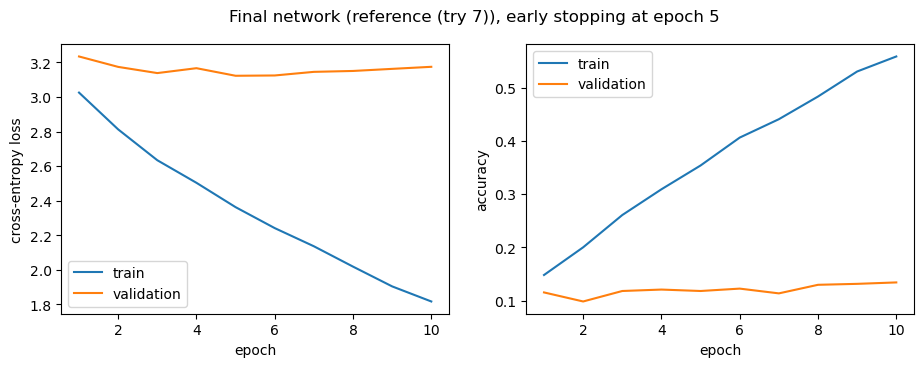

In [13]:
candidate = summary.index[0]
gain = summary.loc[candidate, "best val accuracy"] - p_ref
chosen = candidate if gain > noise else "reference (try 7)"
print(f"candidate: {candidate} (gain {gain * 100:+.1f} points, noise {noise * 100:.1f} points) -> chosen: {chosen}")
chosen_config = configs[chosen]
print("settings:", chosen_config)

torch.manual_seed(0)
final_model = make_pooled_mlp(n_classes, dropout=chosen_config["dropout"],
                              batch_norm=chosen_config["batch_norm"]).to(device)
optimiser_class = torch.optim.AdamW if chosen_config["decoupled"] else torch.optim.Adam
optimizer = optimiser_class(final_model.parameters(), lr=LEARNING_RATE, weight_decay=chosen_config["weight_decay"])
final_history, best_epoch = fit_early_stopping(final_model, style["train_loader"], style["val_loader"], loss_fn, optimizer)
plot_history(final_history, f"Final network ({chosen}), early stopping at epoch {best_epoch}")

**Reading.** The candidate, AdamW with λ = 10, beats the reference by only +0.5 point, less than one standard error (1.0 point), so the rule keeps the reference network (try 7, no regularisation): equal within the noise, the simpler one wins. Retrained with early stopping, it gives exactly the same numbers as in part 3, epoch by epoch (same seed, same machine), which also shows that our early-stopping loop trains exactly like the shared fit. The validation loss is lowest at epoch 5 (3.122); after 5 epochs without improvement, training stops at epoch 10 and the weights of epoch 5 are restored. At that epoch the validation accuracy is only 0.118, below the 0.130–0.134 of epochs 8 to 10: early stopping on the loss keeps the network before it becomes over-confident, not the one with the best accuracy. On such a flat and noisy accuracy curve (0.10–0.14), the difference is about 1.5 standard errors and does not change the conclusion.

### 8.3 Final evaluation on the test set (once) and cost for the kiosk

The final network is measured once on the test images, never used for training nor for any choice.
The cost is measured as in `04_01`: one image, one CPU thread, median of 50 runs after 5 warm-up runs.

In [14]:
final_model.eval()
val_loss, val_acc = evaluate(final_model, style["val_loader"], loss_fn, device=device)
test_loss, test_acc = evaluate(final_model, style["test_loader"], loss_fn, device=device)
print(f"TEST accuracy = {test_acc:.3f} | validation accuracy {val_acc:.3f} | chance {1 / n_classes:.3f}")

# Score of the network without regularisation (04_01), if its results file is there
previous = RES_DIR / "mlp_style.json"
if previous.exists():
    print(f"04_01 (try 7, 12 epochs, no regularisation): test accuracy {json.loads(previous.read_text())['test_accuracy']:.3f}")

TEST accuracy = 0.097 | validation accuracy 0.118 | chance 0.037
04_01 (try 7, 12 epochs, no regularisation): test accuracy 0.115


The final network reaches 0.097 on test (validation 0.118), against 0.115 for try 7 in 04_01. The difference comes first from the epoch kept: 04_01 kept the epoch with the best validation accuracy (12, 0.136), while early stopping on the validation loss keeps epoch 5, a less trained network (validation accuracy 0.118). The rest is noise: −1.7 points is about 19 images out of 1,118, roughly two standard errors, on a task where every MLP stays between 2.5 and 3.5 times chance. We do not change the monitored quantity now: that choice was made before looking at the test set, and changing it after would mean choosing the model on the test.

In [15]:
# --- Cost for the kiosk: time to classify ONE image on ONE CPU thread (as in 04_01) ---
cpu_model = final_model.to("cpu").eval()
x_one = style["X"][:1]  # one standardised image, shape (1, 3, 128, 128)

previous_threads = torch.get_num_threads()
torch.set_num_threads(1)  # simulate a modest kiosk CPU
with torch.no_grad():
    for _ in range(5):
        cpu_model(x_one)  # warm-up: the first runs are slower and are not measured
    times_ms = []
    for _ in range(50):
        start = time.perf_counter()
        cpu_model(x_one)
        times_ms.append((time.perf_counter() - start) * 1000)
torch.set_num_threads(previous_threads)

ms_per_image = float(np.median(times_ms))
size_mb = sum(p.numel() * p.element_size() for p in cpu_model.parameters()) / 1e6

# --- Results file, with the same keys as results/mlp_style.json ---
result = {
    "model": "mlp_pool4_256_128_regularised",
    "label": "style",
    "test_accuracy": round(float(test_acc), 4),
    "cpu_ms_per_image": round(ms_per_image, 2),
    "n_parameters": count_parameters(cpu_model),
    "size_mb": round(size_mb, 1),
    "train_time_s": round(sum(final_history["epoch_time"]), 1),
    "n_classes": n_classes,
    "img_size": 128,
    "pool_size": 4,
    "n_epochs": best_epoch,
    "val_accuracy": round(float(val_acc), 4),
    "regularisation": chosen,
    "dropout": chosen_config["dropout"],
    "batch_norm": chosen_config["batch_norm"],
    "weight_decay": chosen_config["weight_decay"],
    "optimizer": "AdamW" if chosen_config["decoupled"] else "Adam",
    "early_stopping_patience": 5,
}
(RES_DIR / "mlp_reg_style.json").write_text(json.dumps(result, indent=2))
print(json.dumps(result, indent=2))

{
  "model": "mlp_pool4_256_128_regularised",
  "label": "style",
  "test_accuracy": 0.0975,
  "cpu_ms_per_image": 0.08,
  "n_parameters": 823067,
  "size_mb": 3.3,
  "train_time_s": 13.2,
  "n_classes": 27,
  "img_size": 128,
  "pool_size": 4,
  "n_epochs": 5,
  "val_accuracy": 0.1181,
  "regularisation": "reference (try 7)",
  "dropout": 0.0,
  "batch_norm": false,
  "weight_decay": 0.0,
  "optimizer": "AdamW",
  "early_stopping_patience": 5
}


## Conclusions

1. Over-fitting of the reference. Without regularisation the network reaches 91 % on the training images, while its validation loss rises from epoch 5 and its validation accuracy stays flat between 0.10 and 0.14.
2. Weight decay. With Adam, or with AdamW and λ ≤ 0.1, it has no effect. With 2,460 updates in 30 epochs (against 1,110 on the genres) the useful range moves down: λ = 1 has a moderate effect, λ = 10 almost removes the memorisation (18 % training accuracy, lowest validation loss), λ = 30 under-fits and λ = 100 collapses. No λ improves the validation accuracy (best gain +0.5 point).
3. Dropout. It reduces over-fitting in proportion to p (with p = 0.3 the validation loss stays flat), but no rate improves the accuracy; p = 0.5 learns too slowly for 27 classes.
4. Batch norm. It only slows the rise of the validation loss and even makes the network fit the training images slightly better: it is not a regulariser here.
5. Choice and test. No tool beats the reference by more than one standard error (1.0 point), so the reference is kept. Early stopping on the validation loss keeps epoch 5, and the test accuracy is 9.7 %, against 11.4 % in 04_01: an earlier, less trained network, plus noise.
